# Stage C — Precision–Recall, AP e Ranking

Notebook de análise **sem treino**: lê os resultados persistidos da Stage C, apresenta tabelas em formato pandas (sem LaTeX) e cria figuras em PNG.

**Colocação sugerida:** `results/part1/stageC/report.ipynb`, junto de `aps_by_class.csv` e `motorbike/`. Também aceita a estrutura `results/stageC/` ou um ficheiro `stageC.zip` próximo do notebook.

**Saídas:** `report_assets/` (`.csv` e `.png`); as tabelas aparecem diretamente no notebook.

## 1. Carregar os resultados da Stage C

In [1]:
from pathlib import Path
import io
import json
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Localizar a pasta stageC ou o ZIP, a partir do diretório do notebook.
roots = [Path.cwd(), *Path.cwd().parents]
folders = []
zips = []
for root in roots:
    folders.extend([root, root / "stageC", root / "results" / "part1" / "stageC",
                    root / "results" / "stageC", root / "code" / "results" / "part1" / "stageC",
                    root / "code" / "results" / "stageC"])
    zips.append(root / "stageC.zip")

STAGEC_DIR = next((p for p in folders if (p / "aps_by_class.csv").is_file()
                   and (p / "motorbike" / "test" / "ranking.csv").is_file()), None)
STAGEC_ZIP = None if STAGEC_DIR else next((p for p in zips if p.is_file()), None)
if STAGEC_DIR is None and STAGEC_ZIP is None:
    raise FileNotFoundError("Stage C não encontrada: é necessária a pasta stageC ou stageC.zip")

zip_reader = zipfile.ZipFile(STAGEC_ZIP) if STAGEC_ZIP else None
OUT = (STAGEC_DIR if STAGEC_DIR else Path.cwd()) / "report_assets"
OUT.mkdir(parents=True, exist_ok=True)

def csv_stagec(relative_path):
    if STAGEC_DIR is not None:
        return pd.read_csv(STAGEC_DIR / relative_path)
    return pd.read_csv(io.BytesIO(zip_reader.read("stageC/" + relative_path)))

def json_stagec(relative_path):
    if STAGEC_DIR is not None:
        return json.loads((STAGEC_DIR / relative_path).read_text(encoding="utf-8"))
    return json.loads(zip_reader.read("stageC/" + relative_path).decode("utf-8"))

aps = csv_stagec("aps_by_class.csv")
rankings = {s: csv_stagec(f"motorbike/{s}/ranking.csv") for s in ("train", "val", "test")}
curves = {s: csv_stagec(f"motorbike/{s}/precision_recall.csv") for s in ("train", "val", "test")}
run = json_stagec("run.json")

print("Origem:", STAGEC_DIR or STAGEC_ZIP)
print("Saída:", OUT)
print("Estado:", run.get("state", "desconhecido"))
print("Categoria:", aps["category"].unique().tolist())
assert set(rankings) == set(curves) == {"train", "val", "test"}


Origem: c:\IAVC\IAVC_proj_2\code\results\part1\stageC
Saída: c:\IAVC\IAVC_proj_2\code\results\part1\stageC\report_assets
Estado: complete
Categoria: ['motorbike']


## 2. Tabela — AP e Precision@K

**AP** avalia a ordenação dos scores, enquanto **Precision@K** mede a proporção de *motorbikes* entre os primeiros K resultados. A prevalência de positivos é uma referência útil para interpretar o AP.

In [2]:
rows = []
for split in ("train", "val", "test"):
    m = aps.loc[aps["split"] == split].iloc[0]
    rank = rankings[split].sort_values("rank").copy()
    positive = rank["label"].eq(1)
    assert len(rank) == int(m["images"])
    assert int(positive.sum()) == int(m["positives"])
    assert rank["decision_score"].is_monotonic_decreasing
    rows.append({
        "Split": split.capitalize(),
        "Images": int(m["images"]),
        "Positives": int(m["positives"]),
        "Prevalence": float(m["positives"] / m["images"]),
        "AP": float(m["ap"]),
        "P@10": float(positive.head(10).mean()),
        "P@20": float(positive.head(20).mean()),
    })

summary = pd.DataFrame(rows)
display(summary.style.format({"Prevalence": "{:.3f}", "AP": "{:.4f}", "P@10": "{:.2f}", "P@20": "{:.2f}"}))
summary.to_csv(OUT / "stageC_ap_summary.csv", index=False)


,Split,Images,Positives,Prevalence,AP,P@10,P@20
0,Train,911,96,0.105,0.9416,1.00,1.00
1,Val,228,24,0.105,0.5513,0.90,0.55
2,Test,1202,125,0.104,0.4523,0.70,0.65


## 3. Figura — Curva Precision–Recall (teste)

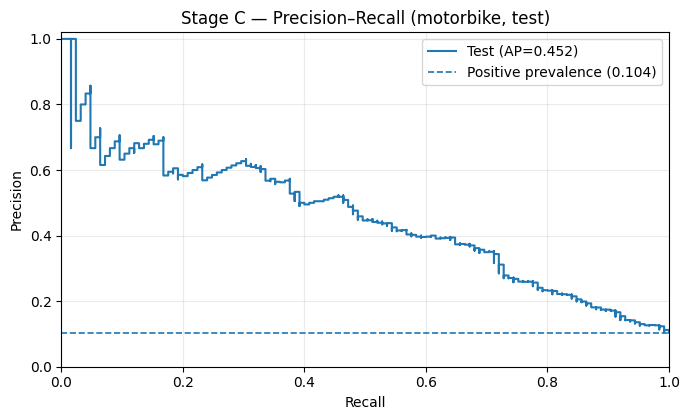

In [3]:
test_pr = curves["test"].sort_values("recall")
test_ap = float(summary.loc[summary["Split"] == "Test", "AP"].iloc[0])
test_prevalence = float(summary.loc[summary["Split"] == "Test", "Prevalence"].iloc[0])

fig, ax = plt.subplots(figsize=(7, 4.3))
ax.step(test_pr["recall"], test_pr["precision"], where="post", label=f"Test (AP={test_ap:.3f})")
ax.axhline(test_prevalence, linestyle="--", linewidth=1.2, label=f"Positive prevalence ({test_prevalence:.3f})")
ax.set(xlabel="Recall", ylabel="Precision", title="Stage C — Precision–Recall (motorbike, test)", xlim=(0, 1), ylim=(0, 1.02))
ax.legend(loc="upper right")
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUT / "stageC_precision_recall_test.png", dpi=300, bbox_inches="tight")
plt.show()


## 4. Figura — Comparação Train / Validation / Test

Esta figura é opcional no relatório; ajuda a visualizar a diferença de desempenho entre os três conjuntos.

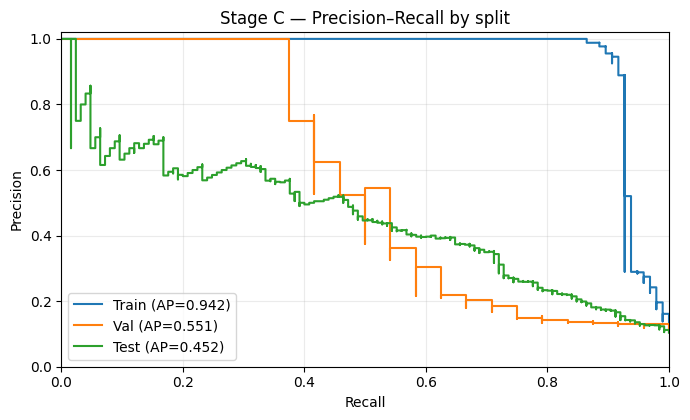

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.3))
for split in ("train", "val", "test"):
    series = curves[split].sort_values("recall")
    ap = float(aps.loc[aps["split"] == split, "ap"].iloc[0])
    ax.step(series["recall"], series["precision"], where="post", label=f"{split.capitalize()} (AP={ap:.3f})")
ax.set(xlabel="Recall", ylabel="Precision", title="Stage C — Precision–Recall by split", xlim=(0, 1), ylim=(0, 1.02))
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUT / "stageC_precision_recall_splits.png", dpi=300, bbox_inches="tight")
plt.show()


## 5. Tabela — Top 10 do ranking de teste

Classes: `motorbike` (positivo) e `background` (negativo). O ranking é ordenado pelo *decision score* do SVM, não por previsão binária.

In [5]:
test_ranking = rankings["test"].sort_values("rank").copy()
rank_table = test_ranking.head(10)[["rank", "image_id", "label", "decision_score"]].copy()
rank_table["class"] = rank_table["label"].map({1: "motorbike", -1: "background"})
rank_table = rank_table[["rank", "image_id", "class", "decision_score"]]
display(rank_table.rename(columns={"rank": "Rank", "image_id": "Image ID", "class": "True class", "decision_score": "SVM score"}).style.format({"SVM score": "{:.4f}"}))
rank_table.to_csv(OUT / "stageC_test_top10.csv", index=False)


,Rank,Image ID,True class,SVM score
0,1,6532,motorbike,1.6780
1,2,4750,motorbike,1.2200
2,3,6687,background,1.1900
3,4,5989,motorbike,1.0810
4,5,499,motorbike,1.0097
5,6,8444,motorbike,0.9864
6,7,8294,motorbike,0.9594
7,8,7356,background,0.9151
8,9,6543,background,0.8814
9,10,6585,motorbike,0.8112


## 6. Tabela — Análise de erros do teste

Esta análise usa o limiar padrão **score = 0** para interpretar decisões binárias. É complementar ao AP, que avalia a ordenação sem limiar. *Hard negatives* são negativos corretamente rejeitados, mas com scores mais elevados (mais próximos do limiar).

In [6]:
r = test_ranking
TP = r[(r["label"] == 1) & (r["decision_score"] >= 0)].sort_values("decision_score", ascending=False)
FN = r[(r["label"] == 1) & (r["decision_score"] < 0)].sort_values("decision_score")
FP = r[(r["label"] == -1) & (r["decision_score"] >= 0)].sort_values("decision_score", ascending=False)
HN = r[(r["label"] == -1) & (r["decision_score"] < 0)].sort_values("decision_score", ascending=False)
TN = r[(r["label"] == -1) & (r["decision_score"] < 0)]

confusion = pd.DataFrame([{"TP": len(TP), "FP": len(FP), "TN": len(TN), "FN": len(FN)}])
display(confusion)
confusion.to_csv(OUT / "stageC_test_confusion.csv", index=False)

examples = pd.concat([
    frame.head(2).assign(group=group)
    for group, frame in [("True positive", TP), ("False negative", FN),
                         ("False positive", FP), ("Hard negative", HN)]
], ignore_index=True)
examples = examples[["group", "rank", "image_id", "label", "decision_score"]]
display(examples.rename(columns={"group": "Group", "rank": "Rank", "image_id": "Image ID", "label": "True label", "decision_score": "SVM score"}).style.format({"SVM score": "{:.4f}"}))
examples.to_csv(OUT / "stageC_test_examples.csv", index=False)


,TP,FP,TN,FN
0,38,24,1053,87


,Group,Rank,Image ID,True label,SVM score
0,True positive,1,6532,1,1.6780
1,True positive,2,4750,1,1.2200
2,False negative,1176,5398,1,-2.7190
3,False negative,1082,7009,1,-2.1817
4,False positive,3,6687,-1,1.1900
5,False positive,8,7356,-1,0.9151
6,Hard negative,64,5224,-1,-0.0065
7,Hard negative,66,9588,-1,-0.0219


## 7. Resumo

**Para o relatório curto:** usar a tabela de AP por split e a figura Precision–Recall de teste. A tabela Top 10 e os exemplos de erro podem fundamentar a discussão, sem necessidade de ocupar espaço no relatório.

**Nota metodológica:** os resultados de teste servem apenas para avaliação final; não devem ser utilizados para voltar a selecionar o vocabulário ou o SVM.